# Flexible code and coding best practice 

Writing code that works is obviously the first step, but how do you write good code? What makes good code better than bad code if it works anyway?

The quality of the code can be seen as being made up of two different elements. 
- How well you use the native capability of python to make your code as efficient as possible.
- The portability of your code which relates to how easy it is to change your code to answer a similar but related question, for example if you get a new version of the data file or want to interrogate the data file for a slightly different set of measurements.

Finally we will look at one piece of bad practice that you must avoid in your coding.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from helper_functions.mcq import mcq_1, mcq_2, mcq_3
print("Cell executed and packages imported successfully")


Cell executed and packages imported successfully


## 1. Put key information at the start

When you want to run a notebook that someone else has written then you want to see what packages you will need, you don't want to get half way through and then find out you need another package that you have not installed. Recall that on Noteable all the packages are already installed but if you were on your own environment you may need to install them before you can use them. This is why best practice is to import all the packages you need at the start of the notebook.

What if you suddenly realise later you need something else? This is fine, but when you have finished move all the imports to one place at the start, rerun the notebook and check it all works

Paths to datafile are also something that you should define once at the start this means that the user can see what is needed and if necessary change the path once at the start. You should only specify the path once in the code. Assign it to a variable and then use it in the rest of your code. This means if you data or data location change then you will only need to change one line of code.

<div class="alert alert-success"><b>Task 1 </b>
Analyse the following code and answer the questions about it below

  Symbol  AtomicNumber  AtomicMass  AtomicRadius_pm Electronegativity
0      H             1      1.0080               53              2.20
1     He             2      4.0026               31                --
2     Li             3      6.9400              167              0.98
3     Be             4      9.0122              112              1.57
4      B             5     10.8100               87              2.04


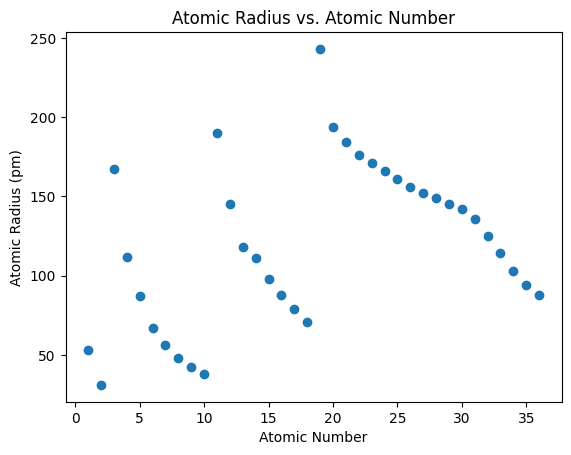

The average atomic radius is: 119.44 pm


In [2]:

import pandas as pd
periodic_df = pd.read_csv("datasets/4_rows_periodic_table.csv")
print(periodic_df.head())

period_df_2 = pd.read_csv("datasets/4_rows_periodic_table.csv")
import matplotlib.pyplot as plt
plt.scatter(periodic_df["AtomicNumber"], periodic_df["AtomicRadius_pm"])
plt.xlabel("Atomic Number")
plt.ylabel("Atomic Radius (pm)")
plt.title("Atomic Radius vs. Atomic Number")
plt.show()

import pandas as pd
mean_radius = periodic_df["AtomicRadius_pm"].mean()
print(f"The average atomic radius is: {mean_radius:.2f} pm")

mcq_1()



In [3]:
mcq_2()

## 2. Use loops and/or functions to avoid repeating code.
Let's say you want to plot multiple graphs or related species etc. You have already seen that the best way to do this is to use a loop rather than just writing the code out in a similar way each time. Loops are good when we want to execute the same block of code in one place and are easy to follow.  Functions are best when we to use the same block of code in multiple places in the same notebook.

## 3. Put parameters that might change into variables
If you are selecting certain parameters from a data set then put these in variables. For example, imagine we wanted to plot data for a selection of countries between certain years.  Putting the country names in one place and the years in one place lets us change these more easily in the future.  You could even put these at the start of the notebook to help. If you do this make sure you name variables sensibly and always use the variable in the code (eg in axis labels and plot titles), don't mix and match variables and hard coding of parameters.

<div class="alert alert-success"><b>Task 2</b>

Here is a block of code that reads some data and plots some graphs relating to the change in Malaria incidence in different countries over a time period (if you run it you will see the output).  Create an optimised version of this code block that avoids repetition and makes it easy to change the countries and range of years displayed. Your answer should give the same output as the long unoptimised version!


In [ ]:
data_file_path ="datasets/falciparum_data.csv"
df = pd.read_csv(data_file_path)
# plot change in Incidence Rate between 2000 and 2025 for Senegal
senegal_data = df[df["Name"] == "Senegal"]
senegal_data_selected_years = senegal_data[senegal_data["Year"].between(2000, 2025)]
fig,ax = plt.subplots()
ax.plot(senegal_data_selected_years["Year"], senegal_data_selected_years["Incidence Rate"], marker="o")
ax.set_title("Change in Incidence Rate of Malaria in Senegal (2000-2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Incidence Rate (per 1000 population)")
plt.show()
# plot change in Incidence Rate between 2000 and 2025 for Nigeria
data_file_path ="datasets/falciparum_data.csv"
df = pd.read_csv(data_file_path)
nigeria_data = df[df["Name"] == "Nigeria"]
nigeria_data_selected_years = nigeria_data[nigeria_data["Year"].between(2000, 2025)]
fig,ax = plt.subplots()
ax.plot(nigeria_data_selected_years["Year"], nigeria_data_selected_years["Incidence Rate"], marker="o")
ax.set_title("Change in Incidence Rate of Malaria in Nigeria (2000-2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Incidence Rate (per 1000 population)")
plt.show()
# plot change in Incidence Rate between 2000 and 2025 for Ghana
data_file_path ="datasets/falciparum_data.csv"
df = pd.read_csv(data_file_path)
ghana_data = df[df["Name"] == "Ghana"] 
ghana_data_selected_years = ghana_data[ghana_data["Year"].between(2000, 2025)]
fig,ax = plt.subplots()
ax.plot(ghana_data_selected_years["Year"], ghana_data_selected_years["Incidence Rate"], marker="o")
ax.set_title("Change in Incidence Rate of Malaria in Ghana (2000-2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Incidence Rate (per 1000 population)")
plt.show()



In [ ]:
# Write your version of the code above here that is more efficient and less repetitive, and then run the cell to check it works correctly

<div class="alert alert-success"><b>Task 3.</b>
In this task we want to get a set of titles of papers from their digital object identifiers.  Optimise the code below, however because you may want to do this a lot you should create a function that will return the title from the doi. By doing this you could reuse the function elsewhere in your notebook.  If your new version works you will get the same output as the unoptimised example

In [ ]:
from Bio import Entrez
# Set your email address (required by NCBI)
email = "youremail@leeds.ac.uk"

doi = '10.1002/anie.202310862'
Entrez.email = email  # Always tell NCBI who you are
stream = Entrez.esearch(db="pubmed", term=doi + '[AID]', retmax="1")
id = Entrez.read(stream)['IdList'][0]
stream = Entrez.esummary(db="pubmed", id=id)
record = Entrez.read(stream)
title = record[0]['Title']
print(f"DOI {doi} has title: {title}")

doi = '10.1038/s42004-024-01163-w'
Entrez.email = email  
stream = Entrez.esearch(db="pubmed", term=doi + '[AID]', retmax="1")
id = Entrez.read(stream)['IdList'][0]
stream = Entrez.esummary(db="pubmed", id=id)
record = Entrez.read(stream)
title = record[0]['Title']
print(f"DOI {doi} has title: {title}")

doi = '10.1126/science.abo7201'
Entrez.email = email  
stream = Entrez.esearch(db="pubmed", term=doi + '[AID]', retmax="1")
id = Entrez.read(stream)['IdList'][0]
stream = Entrez.esummary(db="pubmed", id=id)
record = Entrez.read(stream)
title = record[0]['Title']
print(f"DOI {doi} has title: {title}")

doi = '10.1021/jacs.2c10742'
Entrez.email = email  
stream = Entrez.esearch(db="pubmed", term=doi + '[AID]', retmax="1")
id = Entrez.read(stream)['IdList'][0]
stream = Entrez.esummary(db="pubmed", id=id)
record = Entrez.read(stream)
title = record[0]['Title']
print(f"DOI {doi} has title: {title}")

doi = '10.1039/D3SC00869J'
Entrez.email = email  
stream = Entrez.esearch(db="pubmed", term=doi + '[AID]', retmax="1")
id = Entrez.read(stream)['IdList'][0]
stream = Entrez.esummary(db="pubmed", id=id)
record = Entrez.read(stream)
title = record[0]['Title']
print(f"DOI {doi} has title: {title}")







In [ ]:
# Write you version of the code above here that is more efficient and less repetitive, and then run the cell to check it works correctly
# Hint: you could put the repeated code into a function that takes the DOI and email as a parameter, and then call that function for each DOI in a list of DOIs


## Using dictionaries as control structures.
In the examples above you have probably just looped through a list of values.  In the previous example this made perfect sense as we just wanted to select countries and the country name was also what we wanted to display.  Sometimes however the human readable name of a parameter (eg for plotting etc) isn't the exact value we need to use in our code.  In this case using a dictionary, rather than a list as our control structure can be a useful trick.  Recall dictionaries are key:value pairs.  We can loop through the dictionary using the .items() method, unpacking the key and value in one go.  

<div class ="alert alert-success"> <b> Task 4</b>

Remind yourself of how dictionaries work by executing the following code and answering the questions that follow

In [4]:
capital_cities = {"Senegal": "Dakar", "Nigeria": "Abuja", "Ghana": "Accra"}
for country, capital in capital_cities.items():
    print(f"The capital city of {country} is {capital}.")

The capital city of Senegal is Dakar.
The capital city of Nigeria is Abuja.
The capital city of Ghana is Accra.


In [5]:
mcq_3()

<div class= "alert alert-success"><b>Task 5</b>

The file pollution_data.csv has data for different pollutants and weather measurements in it that you want to plot out over time but not all the column headers are obvious what they mean. For example the column ws stands for wind speed and wd is wind direction. We can not just use the column heading as the axis label.  If we set up a dictionary then we can use the key to be the human readable heading and the value to be the column label. Update the code below to use the dictionary as the controlling structure.


In [ ]:
#Reading in the pollution data and writing the column headings
pollution_data_path = "datasets/pollution_data.csv"
pol_df = pd.read_csv(_________________, parse_dates=["date"])
print(pol_df.columns.tolist())

In [ ]:
# update the parameter dictionary to include the column names for the parameters we want to plot
parameter_dict={"wind speed":____, "wind direction":____}
for __________, ________ in parameter_dict.items():
    #just look at January data to make the plot clearer
    plot_data = pol_df[pol_df["date"].dt.month == 1]
    fig,ax = plt.subplots()
    #create a scatter plot of the parameter over time
    ax.scatter(plot_data["date"], plot_data[_________])
    ax.set_xlabel("Date")
    ax.set_ylabel(_________)
    ax.tick_params(axis='x', labelrotation=90)
    ax.set_title(f"{_________} over time")      
   

Sometimes even a dictionary does not give us enough control in our loop.  In the pollution monitoring data the units of pollutants change depending on the column.  Also we would really like to display species name with subscripts in our graph legends.  The solution is to create a dictionary that holds each parameter for each species.  Then put these dictionaries into a list or another dictionary so we have a list of dictionaries or a dictionary of dictionaries. That we can loop over. For example

In [ ]:
# declare a list of dictionaries to hold the parameter information (this is a more complex data structure, but it allows us to store more information about each parameter
full_parameter_list=[
    {'name': 'wind speed', 'column_name': 'ws', 'units': 'm/s', 'graph_colour': 'blue', 'graph_label': 'Wind Speed / $ms^{-1}$ '},
    {'name': 'wind direction', 'column_name': 'wd', 'units': 'degrees', 'graph_colour': 'orange', 'graph_label': 'Wind Direction / degrees'}#
    ]

for parameter in full_parameter_list:
    plot_data = pol_df[pol_df["date"].dt.month == 1]
    fig,ax = plt.subplots()
    ax.scatter(plot_data["date"], plot_data[parameter["column_name"]], color=parameter["graph_colour"])
    ax.set_xlabel("Date")
    ax.set_ylabel(parameter["graph_label"])
    ax.tick_params(axis='x', labelrotation=90)
    ax.set_title(f"{parameter['name']} over time")

<div class= "alert alert-success"><b>Task 6</b>

Nitrogen monoxide and nitrogen dioxide, PM2.5 and PM10 data are in ug / m<sup>3</sup>. PM stands for particulate matter with a diameter of 2.5 um or less, PM10 are particles with a diameter of <10um.

Update the dictionary so that it includes these definitions and then plot it onto a graph



In [ ]:
full_parameter_list=[
   {'name': 'wind speed', 'column_name': 'ws', 'units': 'm/s', 'graph_colour': 'blue', 'graph_label': 'Wind Speed / $ms^{-1}$ '},
   {'name': 'wind direction', 'column_name': 'wd', 'units': 'degrees', 'graph_colour': 'orange', 'graph_label': 'Wind Direction / degrees'},
   {'name':'Nitrogen Monoxide', _______________________________________________________________________________________________},
   {_______:'Nitrogen Dioxide', _________________________________________________________________________________________________},
   {______:___________, _____________________________________________________________________________________________________},
   _______________________________________________________________________________________________________________________________  
   ]

for parameter in full_parameter_list:
   plot_data = pol_df[pol_df["date"].dt.month == 1]
   fig,ax = plt.subplots()
   ax.scatter(plot_data["date"], plot_data[parameter[_________]], color=_______________)
   ax.set_xlabel("Date")
   ax.set_ylabel(____________)
   ax.tick_params(axis='x', labelrotation=90)
   ax.set_title(f"{______________} over time")

If we had a lot of different parameters to set we could even read this control structure from a file.  An example of this code that you may find useful in the future is shown below.

In [ ]:
# set the file path to the parameter list and read it in as a dataframe
parameter_file = "datasets/parameter_list.csv"
parameter_df = pd.read_csv(parameter_file)
display(parameter_df.head())
#turn the dataframe into a list of dictionaries (one dictionary for each row) - this is a more complex data structure, but it allows us to store more information about each parameter
full_parameter_list=parameter_df.to_dict(orient="records")
print(full_parameter_list)

<div class="alert alert-danger">
 
# 4 NEVER hard code answers between parts of code.
Look at the cells below.  They contain an example of very bad practice, that of hardcoding a result between cells rather than passing it as a variable. In this example we want to see how the value of malaria incidence has changed in the gambia compared to the year 2000.  What the user has done is display the values, look at them and then write the number in the next code cell.  This means if the input data changes the code will then gve the wrong answer!  The correct way to do this is to calculate the value needed and then pass it to the next cell as a variable.

In [ ]:
#it should not be necessary to redo these steps, but they are added to be sure that this code block
# works,as you may have changed something in one of your edits that would cause an error
data_file_path ="datasets/falciparum_data.csv"
df = pd.read_csv(data_file_path)
# Gambia data
gambia_data = df[df["Name"] == "Gambia"]
gambia_data.head()

In [ ]:
# bad practice!!
# calculate difference in Incidence rate compared to 2000 for gambia
# the value for 2000 was displayed in the first row  of the dataframe displayed from the previous code block, but we have hard coded it here to show what not to do 
# The problem here is that if you change the code or data in the above code cell. The code in this cell will not update to give the correct answer, 
# and you would not get an error to alert you to this)
gambia_data["Incidence Rate Difference"] = gambia_data["Incidence Rate"] - 177.950437
gambia_data.head()

In [ ]:
# The correct way to do this is to put the value into a variable
gambia_incidence_rate_2000 = gambia_data[gambia_data["Year"] == 2000]["Incidence Rate"].values[0]
gambia_data["Incidence Rate Difference"] = gambia_data["Incidence Rate"] - gambia_incidence_rate_2000
gambia_data.head()

In [ ]:
fig,ax= plt.subplots()
ax.plot(gambia_data["Year"], gambia_data["Incidence Rate Difference"], marker="o")
ax.set_title("Change in Incidence Rate of Malaria in Gambia (compared to 2000)")
ax.set_xlabel("Year") 
ax.set_ylabel("Incidence Rate Difference (per 1000 population)")
plt.show()